# 02 · Forecasting 16 days of store × family sales

**Task:** forecast daily unit sales for each of the **1,782 store × product-family series** for the next **16 days**
— the horizon a replenishment planner needs to place orders and plan staff.

**Approach**
- One global **LightGBM** model across all series, trained on `log1p(sales)` (so it optimises RMSLE).
- **Direct multi-horizon setup:** every history feature is lagged by ≥ 16 days, so the same model predicts day 1 and
  day 16 of the horizon without ever using data from inside it — no leakage and no recursive error build-up.
- Features chosen from the [EDA](01_eda.ipynb): lags & rolling means, same-weekday averages, promotions (known in
  advance), calendar/payday, national & local holidays, store metadata — see [`src/features.py`](../src/features.py).
- Benchmarked against two baselines a planner could build in a spreadsheet.

**Validation:** rolling-origin backtest over **three consecutive 16-day windows** (29 Jun – 15 Aug 2017); the model is
re-trained from scratch at each cutoff using only data available on that date.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

import style
from features import FEATURES, HORIZON, add_features, load_panel
from forecast import MODELS, fit_lgb, predict_lgb, run_fold, score, summarise

style.apply()
LABELS = {"seasonal_naive": "Seasonal naive (last week)", "weekday_mean_4w": "Same-weekday mean, 4 weeks", "lightgbm": "LightGBM"}

In [2]:
panel = add_features(load_panel())
print(f"{panel.shape[0]:,} rows x {len(FEATURES)} features | "
      f"{panel.groupby(['store_nbr', 'family'], observed=True).ngroups:,} series | "
      f"{panel.date.min().date()} -> {panel.date.max().date()}")

1,466,586 rows x 30 features | 1,782 series | 2015-06-01 -> 2017-08-31


## 1. Backtest

In [3]:
CUTOFFS = ["2017-06-28", "2017-07-14", "2017-07-30"]
results = [run_fold(panel, c) for c in CUTOFFS]
per_fold = summarise(results)
overall = per_fold.groupby("model")[["RMSLE", "WAPE", "Bias"]].mean().loc[MODELS]
overall.style.format({"RMSLE": "{:.3f}", "WAPE": "{:.1%}", "Bias": "{:+.1%}"})

,RMSLE,WAPE,Bias
model,,,
seasonal_naive,0.552,17.0%,-3.1%
weekday_mean_4w,0.462,14.5%,-0.6%
lightgbm,0.397,11.7%,-2.8%


In [4]:
per_fold.pivot(index="cutoff", columns="model", values="WAPE")[MODELS].style.format("{:.1%}")

model,seasonal_naive,weekday_mean_4w,lightgbm
cutoff,,,
2017-06-28,16.3%,13.2%,10.5%
2017-07-14,14.0%,13.1%,12.1%
2017-07-30,20.7%,17.3%,12.4%


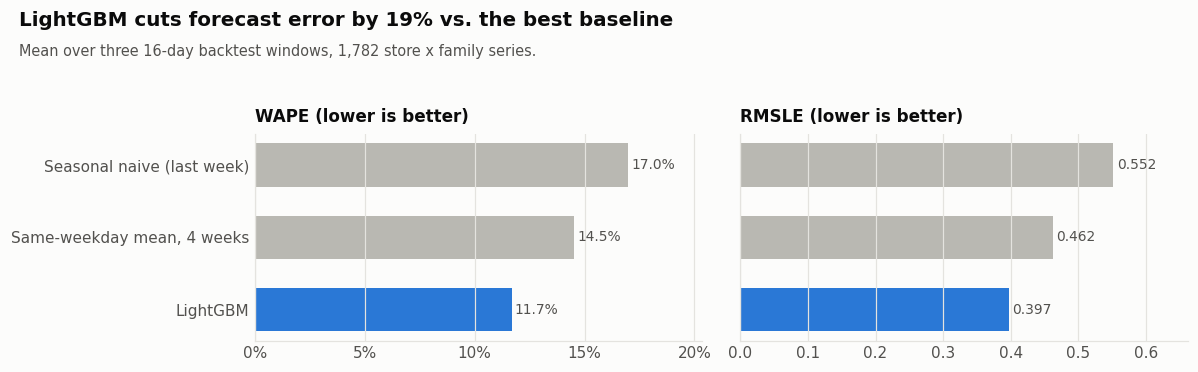

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
colors = [style.MUTED, style.MUTED, style.BLUE]
for ax, metric, fmt in [(axes[0], "WAPE", "{:.1%}"), (axes[1], "RMSLE", "{:.3f}")]:
    vals = overall[metric]
    ax.barh([LABELS[m] for m in MODELS][::-1], vals[::-1], color=colors[::-1], height=0.6)
    for y, v in enumerate(vals[::-1]):
        ax.text(v * 1.01, y, fmt.format(v), va="center", fontsize=9, color=style.TEXT_2)
    ax.grid(True, axis="x"); ax.grid(False, axis="y")
    ax.set_xlim(0, vals.max() * 1.2)
    ax.set_title(f"{metric} (lower is better)", fontsize=11, pad=8)
    if metric == "WAPE":
        ax.xaxis.set_major_locator(mtick.MultipleLocator(0.05))
        ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    else:
        ax.set_yticklabels([])
gain = 1 - overall.loc["lightgbm", "WAPE"] / overall.loc["weekday_mean_4w", "WAPE"]
fig.suptitle(f"LightGBM cuts forecast error by {gain:.0%} vs. the best baseline", x=0.02, ha="left", fontweight="bold", fontsize=13)
fig.text(0.02, 0.86, "Mean over three 16-day backtest windows, 1,782 store x family series.", color=style.TEXT_2, fontsize=9.5)
fig.tight_layout(rect=(0, 0, 1, 0.86))
style.save(fig, "06_model_comparison")
plt.show()

## 2. Where does the model win — and where does it still struggle?

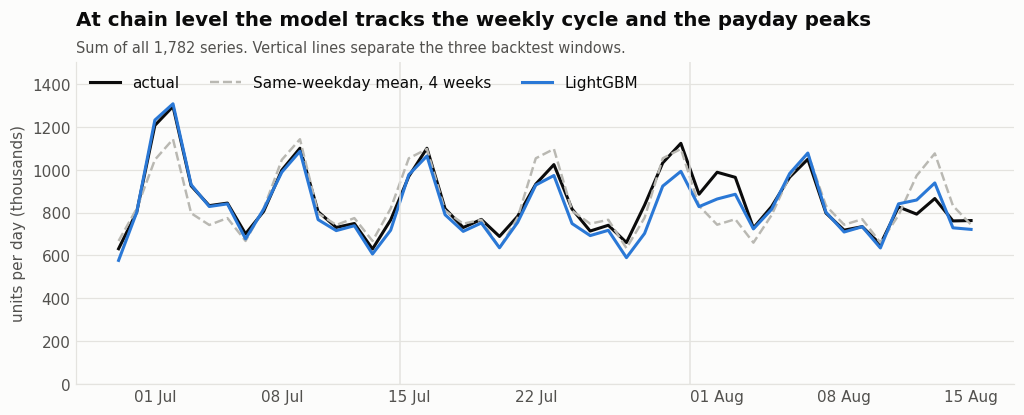

In [6]:
fc = pd.concat([r.forecasts for r in results], ignore_index=True)
chain = fc.groupby("date")[["actual", *MODELS]].sum() / 1e3

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(chain.index, chain.actual, color=style.TEXT, lw=2, label="actual")
ax.plot(chain.index, chain.weekday_mean_4w, color=style.MUTED, lw=1.6, ls="--", label=LABELS["weekday_mean_4w"])
ax.plot(chain.index, chain.lightgbm, color=style.BLUE, lw=2, label=LABELS["lightgbm"])
for c in CUTOFFS[1:]:
    ax.axvline(pd.Timestamp(c) + pd.Timedelta(hours=12), color=style.GRID, lw=1)
ax.set_ylabel("units per day (thousands)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend(loc="upper left", ncols=3)
ax.set_ylim(0, chain.values.max() * 1.15)
ax.set_title("At chain level the model tracks the weekly cycle and the payday peaks")
style.subtitle(ax, "Sum of all 1,782 series. Vertical lines separate the three backtest windows.")
style.save(fig, "07_backtest_chain")
plt.show()

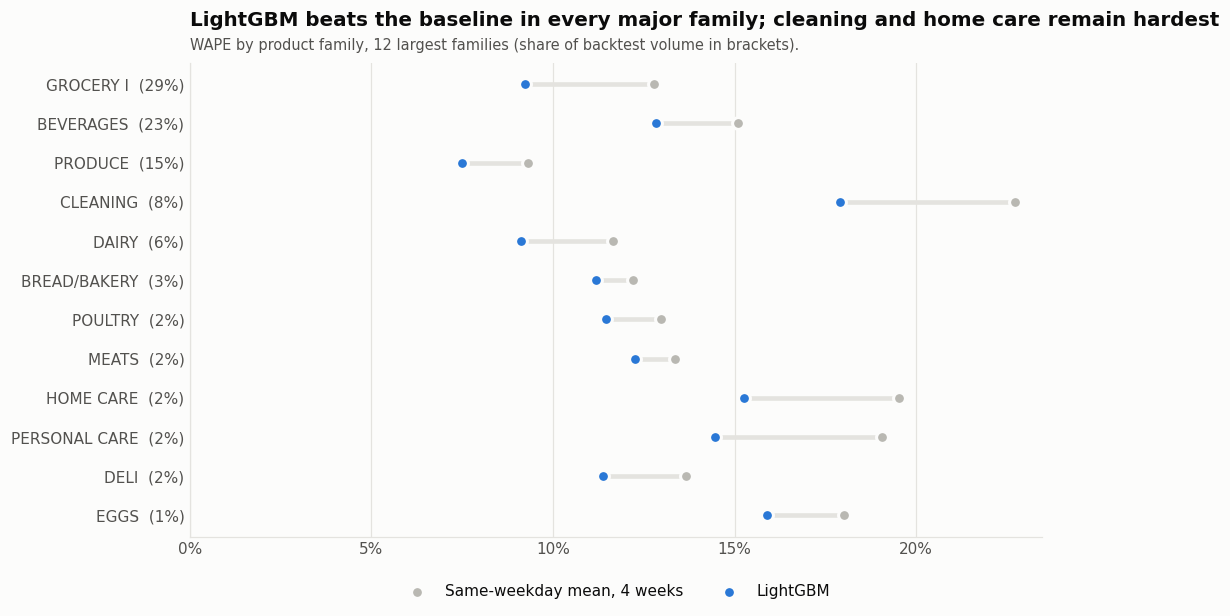

,seasonal_naive,weekday_mean_4w,lightgbm,volume_share
family,,,,
GROCERY I,14.2%,12.8%,9.2%,29.4%
BEVERAGES,18.0%,15.1%,12.8%,22.8%
PRODUCE,9.6%,9.3%,7.5%,14.8%
CLEANING,32.7%,22.7%,17.9%,8.3%
DAIRY,11.8%,11.6%,9.1%,5.5%
BREAD/BAKERY,12.8%,12.2%,11.2%,3.5%
POULTRY,14.9%,13.0%,11.5%,2.5%
MEATS,14.9%,13.3%,12.3%,2.4%
HOME CARE,21.5%,19.5%,15.3%,2.0%


In [7]:
def wape_by(df, key):
    err = df[[key]].assign(**{m: (df.actual - df[m]).abs() for m in MODELS}, actual=df.actual)
    g = err.groupby(key, observed=True).sum()
    out = g[MODELS].div(g.actual, axis=0)
    out["volume_share"] = g.actual / g.actual.sum()
    return out

fam_err = wape_by(fc, "family").sort_values("volume_share", ascending=False)
top = fam_err.head(12).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 5.6))
ax.grid(True, axis="x"); ax.grid(False, axis="y")
y = np.arange(len(top))
ax.hlines(y, top.lightgbm, top.weekday_mean_4w, color=style.GRID, lw=3)
ax.scatter(top.weekday_mean_4w, y, color=style.MUTED, s=60, zorder=3, label=LABELS["weekday_mean_4w"], edgecolor=style.SURFACE, linewidth=2)
ax.scatter(top.lightgbm, y, color=style.BLUE, s=60, zorder=3, label=LABELS["lightgbm"], edgecolor=style.SURFACE, linewidth=2)
ax.set_yticks(y, [f"{f}  ({s:.0%})" for f, s in zip(top.index, top.volume_share)])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlim(0, None)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncols=2)
ax.set_title("LightGBM beats the baseline in every major family; cleaning and home care remain hardest")
style.subtitle(ax, "WAPE by product family, 12 largest families (share of backtest volume in brackets).")
style.save(fig, "08_error_by_family")
plt.show()
fam_err.head(12).style.format("{:.1%}")

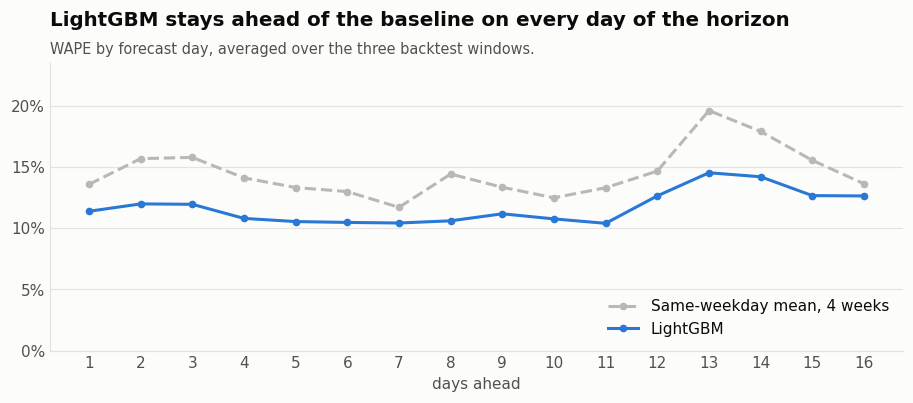

In [8]:
hz = wape_by(fc, "horizon_day")

fig, ax = plt.subplots(figsize=(10, 3.4))
for m, c, ls in [("weekday_mean_4w", style.MUTED, "--"), ("lightgbm", style.BLUE, "-")]:
    ax.plot(hz.index, hz[m], color=c, lw=2, ls=ls, marker="o", ms=4, label=LABELS[m])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_ylim(0, hz[["weekday_mean_4w", "lightgbm"]].values.max() * 1.2)
ax.set_xticks(range(1, HORIZON + 1))
ax.set_xlabel("days ahead")
ax.legend(loc="lower right")
ax.set_title("LightGBM stays ahead of the baseline on every day of the horizon")
style.subtitle(ax, "WAPE by forecast day, averaged over the three backtest windows.")
style.save(fig, "09_error_by_horizon")
plt.show()

## 3. What the model relies on

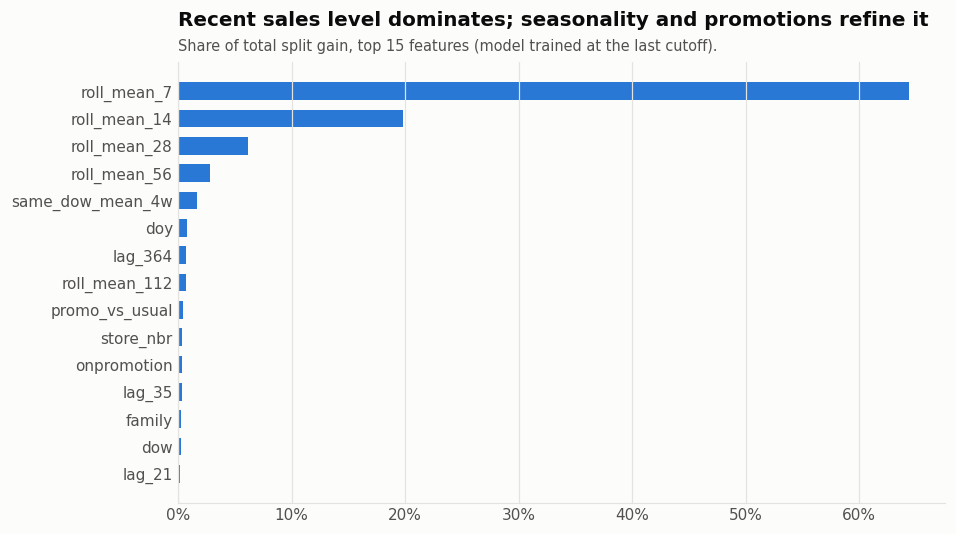

In [9]:
model = results[-1].model
imp = pd.Series(model.feature_importance("gain"), index=model.feature_name()).sort_values()
imp = imp / imp.sum()
top_imp = imp.tail(15)

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.grid(True, axis="x"); ax.grid(False, axis="y")
ax.barh(top_imp.index, top_imp.values, color=style.BLUE, height=0.65)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_title("Recent sales level dominates; seasonality and promotions refine it")
style.subtitle(ax, "Share of total split gain, top 15 features (model trained at the last cutoff).")
style.save(fig, "10_feature_importance")
plt.show()

## 4. One series up close

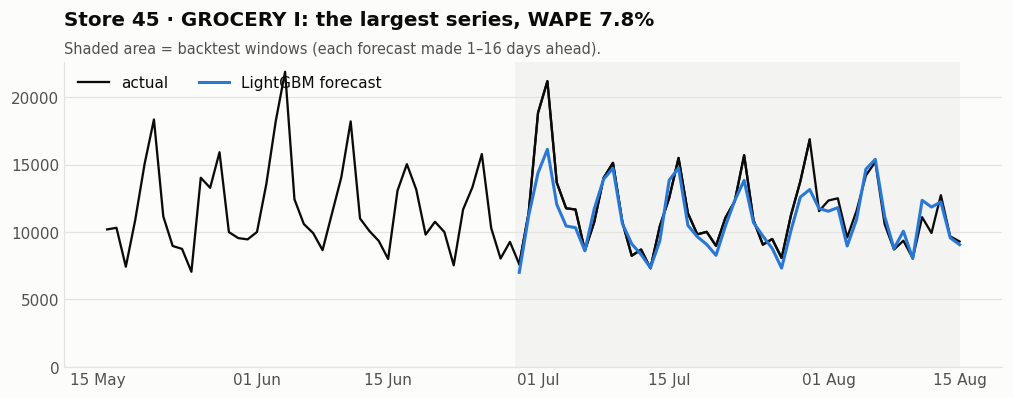

In [10]:
key = fc.groupby(["store_nbr", "family"], observed=True).actual.sum().idxmax()
hist = panel[(panel.store_nbr == key[0]) & (panel.family == key[1]) & (panel.date > "2017-05-15") & (panel.date <= CUTOFFS[-1])]
one = fc[(fc.store_nbr == key[0]) & (fc.family == key[1])]

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(hist.date, hist.sales, color=style.TEXT, lw=1.5, label="actual")
ax.plot(one.date, one.actual, color=style.TEXT, lw=1.5)
ax.plot(one.date, one.lightgbm, color=style.BLUE, lw=2, label="LightGBM forecast")
ax.axvspan(pd.Timestamp(CUTOFFS[0]) + pd.Timedelta(hours=12), one.date.max(), color=style.GRID, alpha=0.35, lw=0)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend(loc="upper left", ncols=3)
ax.set_ylim(0, None)
s = score(one.actual, one.lightgbm)
ax.set_title(f"Store {key[0]} · {key[1]}: the largest series, WAPE {s['WAPE']:.1%}")
style.subtitle(ax, "Shaded area = backtest windows (each forecast made 1–16 days ahead).")
style.save(fig, "11_example_series")
plt.show()

## 5. Production forecast: 16 – 31 August 2017

Re-train on all data up to 15 August and forecast the real (unseen) Kaggle test period.

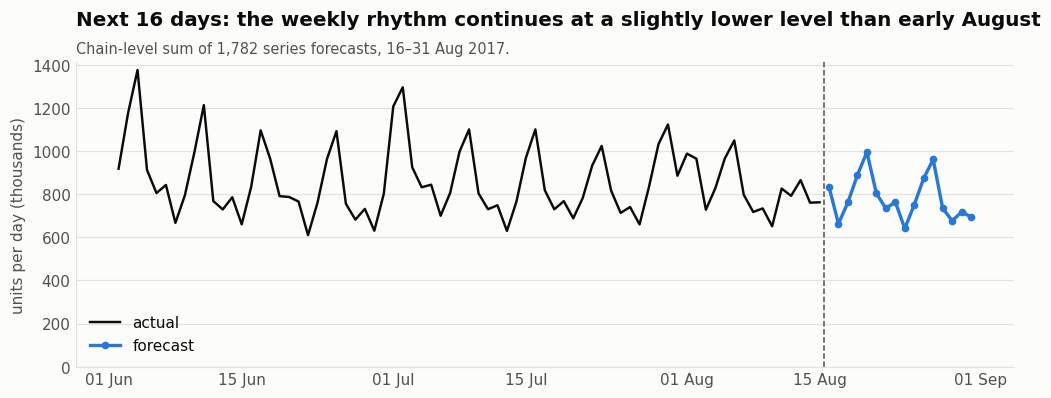

Forecast total for 16-31 Aug: 12.50M units (last 16 days actual: 13.32M)


In [11]:
final = fit_lgb(panel[panel.date <= "2017-08-15"])
future = panel[panel.date > "2017-08-15"].copy()
future["forecast"] = predict_lgb(final, future)
recent = panel[(panel.date > "2017-08-15") | (panel.date > "2017-06-01")]
dead = (panel[panel.date > pd.Timestamp("2017-08-15") - pd.Timedelta(days=56)]
        .query("date <= '2017-08-15'").groupby(["store_nbr", "family"], observed=True).sales.sum())
dead = dead[dead == 0].index
mask = pd.MultiIndex.from_frame(future[["store_nbr", "family"]].astype(object)).isin(dead)
future.loc[mask, "forecast"] = 0

past = panel[(panel.date > "2017-06-01") & (panel.date <= "2017-08-15")].groupby("date").sales.sum() / 1e3
ahead = future.groupby("date").forecast.sum() / 1e3

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(past.index, past.values, color=style.TEXT, lw=1.6, label="actual")
ax.plot(ahead.index, ahead.values, color=style.BLUE, lw=2.2, marker="o", ms=4, label="forecast")
ax.axvline(pd.Timestamp("2017-08-15 12:00"), color=style.TEXT_2, lw=1, ls="--")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_ylim(0, None)
ax.set_ylabel("units per day (thousands)")
ax.legend(loc="lower left")
ax.set_title("Next 16 days: the weekly rhythm continues at a slightly lower level than early August")
style.subtitle(ax, "Chain-level sum of 1,782 series forecasts, 16–31 Aug 2017.")
style.save(fig, "12_production_forecast")
plt.show()
print(f"Forecast total for 16-31 Aug: {future.forecast.sum() / 1e6:.2f}M units "
      f"(last 16 days actual: {panel[(panel.date > '2017-07-30') & (panel.date <= '2017-08-15')].sales.sum() / 1e6:.2f}M)")

## 6. Results & business takeaways

| | Seasonal naive | Same-weekday mean (4w) | **LightGBM** |
|---|---|---|---|
| WAPE | 17.0% | 14.5% | **11.7%** |
| RMSLE | 0.552 | 0.462 | **0.397** |
| Bias | −3.1% | −0.6% | −2.8% |

- **19% lower forecast error than the best spreadsheet-style baseline**, and LightGBM wins in **all three** backtest
  windows and in **every one** of the 12 largest product families.
- For the three biggest families (GROCERY I, BEVERAGES, PRODUCE: 67% of volume) WAPE is **7.5–12.8%**. Lower error
  on perishables means less safety stock and fewer markdowns and stock-outs.
- CLEANING, HOME CARE and PERSONAL CARE improve the most in absolute terms (−4 to −5 pts) but remain the hardest
  (15–18% WAPE). Their demand is driven by promotions and stock-up trips, so these are the categories where a
  planner's overrides still add the most value.
- The model is **slightly under-forecasting (−2.8%)**, mostly on the **month-start payday peaks** (e.g. 1–3 Aug).
  A replenishment process should correct that bias before converting forecasts into orders.

**Next steps**
1. Separate models (or a horizon feature with shorter lags) for days 1–7, where more recent data is available.
2. Explicit month-start / payday interaction features and a bias-correction layer to fix the under-forecast on peak days.
3. Prediction intervals (quantile objective) so safety stock can be set per series from forecast uncertainty.
4. Promotion *depth* and price data, which this dataset lacks, to model the promo response properly.
